# SANAD RC3 — Accelerated CPU (Google Drive API / mount-free revision)

**Drive-mount failure fixed at the integration layer:** The notebook does **not** call `drive.mount()`. Colab authenticates to the Google Drive REST API directly and uses temporary `/content/` storage. It uploads all final metrics to a new `SANAD_RC3_ACCELERATED_V1_RESULTS` folder in **My Drive**.

**Frozen model unchanged:** SHA-verified SANAD RC3 7×8, threshold 0.50, original v35 model and source. This is replay of the original Sionna simulation evidence, **not independent field qualification**.

**Latency:** Ordinary report ingestion and 300th-report terminal scoring are measured separately. Even if both are less than 10ms, they **do not** prove earlier fault-detection time. A full 144-seed parity check must pass.

**How to run:** In Google Colab, choose `Runtime → Run all`. When Google prompts, authenticate with the **same account that owns your SANAD Drive files**. There is **no DriveFS mounting step**. A new Colab runtime loses its temporary cache, so missing source files will be downloaded again. Intermediate results are saved to Drive when parity succeeds.


In [3]:
# 1 — Pin versions in the scoring subprocess; avoid preloaded Colab NumPy state.
import sys, subprocess
assert sys.version_info >= (3,11),sys.version
subprocess.run([sys.executable,'-m','pip','install','-q',
    'numpy==2.3.5','scikit-learn==1.8.0','joblib==1.5.3',
    'numba==0.65.1','llvmlite==0.47.0',
    'google-api-python-client>=2.100','google-auth>=2.20',
    'matplotlib>=3.8'],check=True)
subprocess.run([sys.executable,'-c',
    "import numpy,sklearn,joblib,numba,llvmlite;print('SCORER_ENV',numpy.__version__,sklearn.__version__,joblib.__version__,numba.__version__,llvmlite.__version__);assert (numpy.__version__,sklearn.__version__,joblib.__version__,numba.__version__,llvmlite.__version__)==('2.3.5','1.8.0','1.5.3','0.65.1','0.47.0')"],check=True)
print('Fresh scoring interpreter verified; no kernel NumPy imports required.')

Fresh scoring interpreter verified; no kernel NumPy imports required.


In [4]:
# 2 — Authenticate directly to Drive API; bypass DriveFS.
# DriveFS sometimes fails in Colab even when the Google Drive REST API works.
from google.colab import auth
from google.auth import default
from googleapiclient.discovery import build
from googleapiclient.errors import HttpError
from googleapiclient.http import MediaIoBaseDownload, MediaFileUpload
from pathlib import Path
import hashlib, zipfile, os, stat, subprocess, time, sys, shutil, json, io

# Colab Drive API OAuth is independent of the DriveFS mount service.
auth.authenticate_user()
try:
    creds, _ = default(scopes=['https://www.googleapis.com/auth/drive'])
    if not creds.valid:
        raise RuntimeError('No active user credentials')
except Exception:
    print('Authenticate with the same Google account that owns the SANAD files.')
    auth.authenticate_user()
    creds, _ = default(scopes=['https://www.googleapis.com/auth/drive'])
service=build('drive', 'v3', credentials=creds, cache_discovery=False)

# The CPU experiment uses LOCAL Colab storage. It does not require Drive mounting.
ROOT_BASE=Path('/content/SANAD_RC3_WORK')
ROOT_BASE.mkdir(parents=True, exist_ok=True)
OUT=ROOT_BASE/'SANAD_RC3_ACCELERATED_V1_RESULTS'
CACHE=ROOT_BASE/'verified_evidence_cache'
OUT.mkdir(exist_ok=True, parents=True)
for role in ('qualification','checkpoints'):(CACHE/role).mkdir(exist_ok=True,parents=True)
DRIVE_RESULT_FOLDER='SANAD_RC3_ACCELERATED_V1_RESULTS'
DRIVE_MODE='GOOGLE_DRIVE_API_NO_MOUNT'

def retry_api(op, label):
    for attempt in range(10):
        try:
            return op()
        except HttpError as e:
            status=getattr(getattr(e,'resp',None),'status',0)
            msg=str(e).lower()
            retryable = status in (429,500,502,503,504) or (status==403 and ('ratelimit' in msg or 'quota' in msg))
            if not retryable or attempt == 9:
                raise RuntimeError(f'Drive API {label} failed (HTTP {status}). Confirm Colab is logged into the same Google account.') from e
            seconds=min(60,2**min(attempt+2,6))
            print(f'Drive API {label} rate-limited; retrying in {seconds}s',flush=True)
            time.sleep(seconds)

def download_drive_file(file_id, target):
    target=Path(target)
    target.parent.mkdir(exist_ok=True,parents=True)
    partial=target.with_name(target.name+'.partial')
    if partial.exists():partial.unlink()
    try:
        req=service.files().get_media(fileId=file_id)
        with partial.open('wb') as stream:
            task=MediaIoBaseDownload(stream,req,chunksize=2**20)
            done=False
            while not done:
                _,done=retry_api(lambda:task.next_chunk(), 'download '+target.name)
        if partial.stat().st_size==0:raise RuntimeError('Empty Drive download: '+target.name)
        partial.replace(target)
    finally:
        partial.unlink(missing_ok=True)
    return target

def get_result_folder():
    name=DRIVE_RESULT_FOLDER.replace("'","\\'")
    q=("'root' in parents and trashed = false and "
       "mimeType = 'application/vnd.google-apps.folder' and name = '"+name+"'")
    found=retry_api(lambda:service.files().list(q=q,fields='nextPageToken,files(id,name)',pageSize=100).execute(), 'find output folder').get('files',[])
    if len(found)>1:raise RuntimeError('Multiple root result folders have the same name; resolve duplicates before saving.')
    if found:return found[0]['id']
    created=retry_api(lambda:service.files().create(body={'name':DRIVE_RESULT_FOLDER,
        'mimeType':'application/vnd.google-apps.folder','parents':['root']},fields='id,name').execute(), 'create output folder')
    return created['id']

def upload_results(paths):
    folder_id=get_result_folder()
    for file in paths:
        file=Path(file)
        if not file.is_file():continue
        name=file.name.replace("'","\\'")
        q=f"'{folder_id}' in parents and trashed = false and name = '{name}'"
        present=retry_api(lambda:service.files().list(q=q,fields='files(id,name)',pageSize=10).execute(), 'find '+name).get('files',[])
        if len(present)>1:raise RuntimeError('Duplicate result filename '+name)
        mime='image/png' if file.suffix.lower()=='.png' else 'application/json'
        media=MediaFileUpload(str(file),mimetype=mime,resumable=False)
        if present:
            retry_api(lambda:service.files().update(fileId=present[0]['id'],media_body=media,fields='id,name').execute(), 'update '+name)
        else:
            retry_api(lambda:service.files().create(body={'name':file.name,'parents':[folder_id]},media_body=media,fields='id,name').execute(), 'upload '+name)
        print('SAVED_TO_DRIVE',file.name,flush=True)
    print('DRIVE_RESULT_FOLDER','https://drive.google.com/drive/folders/'+folder_id,flush=True)

print('Drive API authenticated. File mounts are NOT required.')
print('Local output:',OUT)
print('Local verified evidence cache:',CACHE)


Authenticate with the same Google account that owns the SANAD files.
Drive API authenticated. File mounts are NOT required.
Local output: /content/SANAD_RC3_WORK/SANAD_RC3_ACCELERATED_V1_RESULTS
Local verified evidence cache: /content/SANAD_RC3_WORK/verified_evidence_cache


In [5]:
# 3 — Download the original locked package by its exact Drive ID; no DriveFS or git clone.
BUNDLE=ROOT_BASE/'SANAD_RC3_Accelerated_Stateful_CPU_V1.zip'
BUNDLE_ID='1REuwFrGpnEfUre_jfFeGx7dpQZ6Tz8om'
BUNDLE_SHA='9fb7ef8644554f7abf049a2d83712c60b42b1dae678882b40694c13bbb826c49'
ROOT=Path('/content/SANAD_RC3_ACCELERATED_V1')
def digest(p,algorithm='sha256'):
    h=hashlib.new(algorithm)
    with open(p,'rb') as f:
        for chunk in iter(lambda:f.read(2**20),b''):h.update(chunk)
    return h.hexdigest()
if not BUNDLE.exists() or digest(BUNDLE)!=BUNDLE_SHA:
    download_drive_file(BUNDLE_ID,BUNDLE)
if digest(BUNDLE)!=BUNDLE_SHA:
    raise RuntimeError('Refusing to load: private RC3 ZIP checksum does not match pinned source.')
if ROOT.exists():shutil.rmtree(ROOT)
ROOT.mkdir(parents=True)
with zipfile.ZipFile(BUNDLE) as zipfile_obj:
    names=set();total=0
    entries=zipfile_obj.infolist()
    if not 20<=len(entries)<=150:raise RuntimeError('Unexpected package file count')
    for item in entries:
        p=Path(item.filename)
        mode=(item.external_attr>>16)&0o170000
        if (item.is_dir() or p.is_absolute() or '..' in p.parts or item.filename in names
            or mode not in (0,stat.S_IFREG)):
            raise RuntimeError('Unsafe package member: '+item.filename)
        names.add(item.filename);total+=item.file_size
        if item.file_size>7_000_000 or total>30_000_000:raise RuntimeError('Oversized package member')
        dst=ROOT/p;dst.parent.mkdir(parents=True,exist_ok=True)
        with zipfile_obj.open(item) as source,open(dst,'xb') as output:
            shutil.copyfileobj(source,output,length=2**20)
subprocess.run([sys.executable,str(ROOT/'frozen'/'verify_portable.py')],check=True)
print('Frozen model and original source independently hash-verified. SHA:',BUNDLE_SHA)


Frozen model and original source independently hash-verified. SHA: 9fb7ef8644554f7abf049a2d83712c60b42b1dae678882b40694c13bbb826c49


In [6]:
# 4 — Original 144 evidence NPZ + 144 checkpoint JSON, downloaded directly by Drive API.
SOURCE_FOLDERS={
    'qualification':'1yoKqnablDwjOLadUz4eAcY9QDPtemW8x',
    'checkpoints':'1N9XK2W_Vh-Cr3o6HoO1T_1aP3ewf7MmV'}
EXPECTED={
    'qualification':[f's{x}.npz' for x in range(3000,3144)],
    'checkpoints':[f's{x}.json' for x in range(3000,3144)]}

def list_folder(fid):
    result={}; token=None
    while True:
        kwargs={'q':f"'{fid}' in parents and trashed = false",
          'fields':'nextPageToken,files(id,name,size,md5Checksum,mimeType)',
          'pageSize':1000,'supportsAllDrives':True,'includeItemsFromAllDrives':True}
        if token:kwargs['pageToken']=token
        page=retry_api(lambda:service.files().list(**kwargs).execute(), 'source listing')
        for item in page.get('files',[]):
            if item['name'] in result:raise ValueError('Duplicate evidence filename: '+item['name'])
            result[item['name']]=item
        token=page.get('nextPageToken')
        if not token:break
    return result
index={key:list_folder(value) for key,value in SOURCE_FOLDERS.items()}
for role,required in EXPECTED.items():
    missing=set(required)-set(index[role])
    if missing:raise RuntimeError(f'Missing {len(missing)} original {role} files: {sorted(missing)[:5]}')

def ensure(role,name):
    meta=index[role][name]; dst=CACHE/role/name
    expected_size=int(meta['size']); md5=meta.get('md5Checksum')
    if dst.is_file() and dst.stat().st_size==expected_size and (not md5 or digest(dst,'md5')==md5):
        return dst
    for attempt in range(4):
        try:
            download_drive_file(meta['id'],dst)
            if dst.stat().st_size!=expected_size or (md5 and digest(dst,'md5')!=md5):
                dst.unlink(missing_ok=True)
                raise IOError('Size/checksum mismatch: '+name)
            time.sleep(.35) # Light pacing avoids per-user API spikes.
            return dst
        except IOError:
            dst.unlink(missing_ok=True)
            if attempt==3:raise
            time.sleep(2**attempt)
    raise AssertionError('Unreachable downloader state')

for role,files in EXPECTED.items():
    for i,name in enumerate(files,1):
        ensure(role,name)
        if i%36==0:print('VERIFIED',role,i,'/',len(files),flush=True)
print('READY: All 144 original qualification NPZ and 144 checkpoint JSON verified via API')


VERIFIED qualification 36 / 144
VERIFIED qualification 72 / 144
VERIFIED qualification 108 / 144
VERIFIED qualification 144 / 144
VERIFIED checkpoints 36 / 144
VERIFIED checkpoints 72 / 144
VERIFIED checkpoints 108 / 144
VERIFIED checkpoints 144 / 144
READY: All 144 original qualification NPZ and 144 checkpoint JSON verified via API


In [7]:
# 5 — Validate code and reject invalid inputs before full evaluation.
ENV={**os.environ,'OPENBLAS_NUM_THREADS':'1','OMP_NUM_THREADS':'1',
     'MKL_NUM_THREADS':'1','NUMBA_NUM_THREADS':'1','PYTHONUNBUFFERED':'1'}
preflight=[CACHE/'qualification'/f's{x}.npz' for x in (3044,3054,3069,3084,3099,3114,3129,3143)]
subprocess.run([sys.executable,str(ROOT/'tests.py'),*map(str,preflight),
               '--output',str(OUT/'regression_preflight.json')],
               cwd=str(ROOT),env=ENV,check=True)
subprocess.run([sys.executable,str(ROOT/'edge_cases.py'),str(CACHE/'qualification'/'s3143.npz'),
    '--output',str(OUT/'edge_cases_preflight.json')],cwd=str(ROOT),env=ENV,check=True)
print('All 8 seeds / 16 streams plus 5 edge scenarios passed parity tests.')

All 8 seeds / 16 streams plus 5 edge scenarios passed parity tests.


In [8]:
# 6 — FULL 144-SEED PARITY + latency benchmark on original frozen Sionna traces.
# No training, model changes, test-set thresholds or new fault injections.
subprocess.run([sys.executable,str(ROOT/'validate_full.py'),
    '--evidence',str(CACHE/'qualification'),
    '--checkpoints',str(CACHE/'checkpoints'),
    '--out',str(OUT),'--start','3000','--end','3143'],
    cwd=str(ROOT),env=ENV,check=True)
RESULT=json.loads((OUT/'fast_latency_and_parity_summary.json').read_text())
assert RESULT['status']=='FULL_PARITY_PASS'
assert RESULT['completed_seeds']==144 and RESULT['totals']['tp']==274
assert RESULT['totals']['healthy_fp']==0 and RESULT['totals']['neighbor_fp']==13
print('ALL 144 ORIGINAL RC3 CHECKPOINTS MATCH. Accelerated implementation parity PASS.')
# Persist the verified results immediately; no Drive mounting required.
upload_results([OUT/'fast_latency_and_parity_summary.json',OUT/'fast_per_seed_details.json',
                OUT/'regression_preflight.json',OUT/'edge_cases_preflight.json',OUT/'progress_latest.json'])


ALL 144 ORIGINAL RC3 CHECKPOINTS MATCH. Accelerated implementation parity PASS.
SAVED_TO_DRIVE fast_latency_and_parity_summary.json
SAVED_TO_DRIVE fast_per_seed_details.json
SAVED_TO_DRIVE regression_preflight.json
SAVED_TO_DRIVE edge_cases_preflight.json
SAVED_TO_DRIVE progress_latest.json
DRIVE_RESULT_FOLDER https://drive.google.com/drive/folders/1NZ_gKkIWZfLMrHsV1HXPXoKSfqnzOV9j


FROZEN_PARITY: FULL_PARITY_PASS; 144/144 seeds; model unchanged
Full-window p95: original=842.404 ms; optimized=453.839 ms
Stateful ingestion p95: ordinary report=1.956 ms; final scoring report=11.632 ms
Cold startup incl. JIT=761.0 ms
Important: RC3 first-alert TTD is unavailable; no detection-time improvement is claimed.


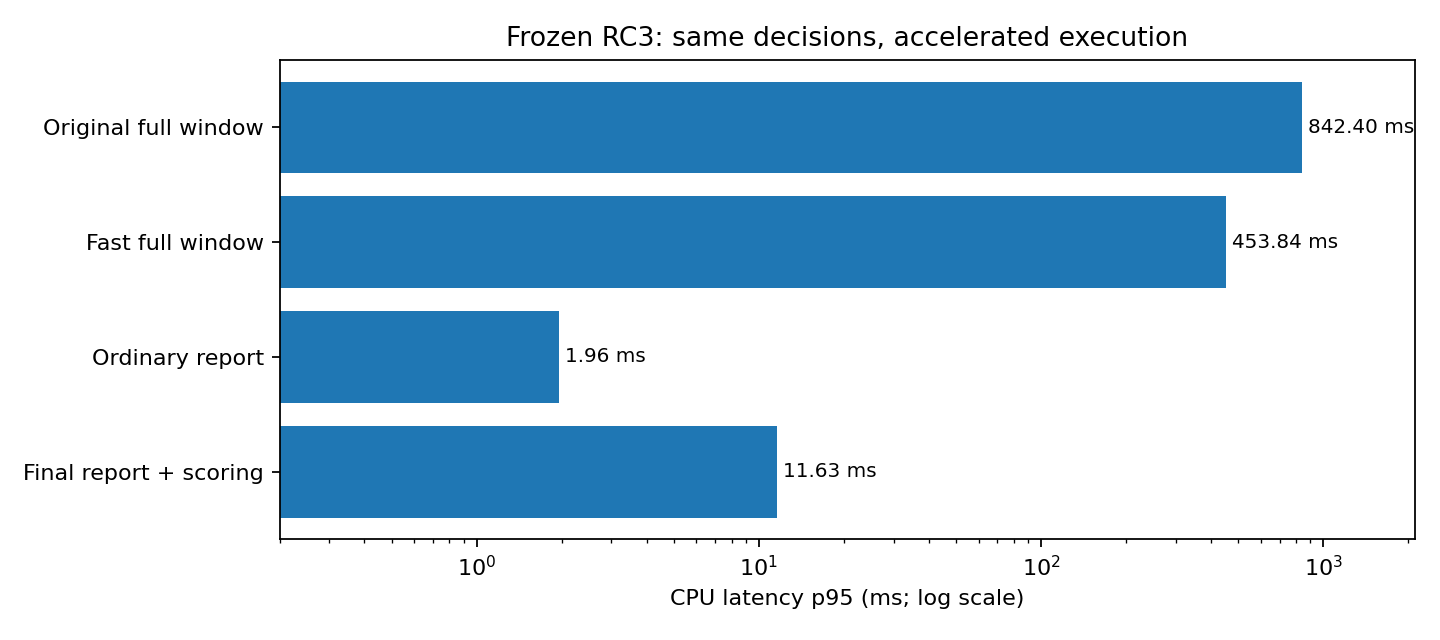

JSON_REPORT: /content/SANAD_RC3_WORK/SANAD_RC3_ACCELERATED_V1_RESULTS/fast_latency_and_parity_summary.json
SEED_DETAILS: /content/SANAD_RC3_WORK/SANAD_RC3_ACCELERATED_V1_RESULTS/fast_per_seed_details.json
REFERENCE: Original RC3 95.14% recall and 0/1008 healthy-only false alerts were simulation results, NOT new validation.
SAVED_TO_DRIVE execution_latency_p95.png
DRIVE_RESULT_FOLDER https://drive.google.com/drive/folders/1NZ_gKkIWZfLMrHsV1HXPXoKSfqnzOV9j


In [9]:
# 7 — Client-ready performance summary (NOT fault TTD or field recall).
from IPython.display import display,Markdown,Image
s=json.loads((OUT/'fast_latency_and_parity_summary.json').read_text())
orig=s['original_full_300_report_stream']['p95_ms']
fast=s['fast_full_300_report_stream']['p95_ms']
ordinary=s['incremental_ordinary_report_update']['p95_ms']
final=s['incremental_final_report_including_scoring']['p95_ms']
print(f'FROZEN_PARITY: {s["status"]}; 144/144 seeds; model unchanged')
print(f'Full-window p95: original={orig:.3f} ms; optimized={fast:.3f} ms')
print(f'Stateful ingestion p95: ordinary report={ordinary:.3f} ms; final scoring report={final:.3f} ms')
print(f'Cold startup incl. JIT={s["cold_engine_startup_including_jit_ms"]:.1f} ms')
print('Important: RC3 first-alert TTD is unavailable; no detection-time improvement is claimed.')
plot=r"""
import sys,json
from pathlib import Path
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
p=Path(sys.argv[1]);d=json.loads((p/'fast_latency_and_parity_summary.json').read_text())
names=['Original full window','Fast full window','Ordinary report','Final report + scoring']
vals=[d['original_full_300_report_stream']['p95_ms'],d['fast_full_300_report_stream']['p95_ms'],d['incremental_ordinary_report_update']['p95_ms'],d['incremental_final_report_including_scoring']['p95_ms']]
fig,ax=plt.subplots(figsize=(9,4));ax.barh(names,vals)
ax.set_xscale('log');ax.set_xlabel('CPU latency p95 (ms; log scale)');ax.set_title('Frozen RC3: same decisions, accelerated execution')
for i,v in enumerate(vals):ax.text(v*1.05,i,f'{v:.2f} ms',va='center',fontsize=9)
ax.invert_yaxis();ax.set_xlim(.2,max(vals)*2.5);fig.tight_layout()
fig.savefig(p/'execution_latency_p95.png',dpi=160)
"""
subprocess.run([sys.executable,'-c',plot,str(OUT)],env=ENV,check=True)
display(Image(filename=str(OUT/'execution_latency_p95.png')))
print('JSON_REPORT:',OUT/'fast_latency_and_parity_summary.json')
print('SEED_DETAILS:',OUT/'fast_per_seed_details.json')
print('REFERENCE: Original RC3 95.14% recall and 0/1008 healthy-only false alerts were simulation results, NOT new validation.')
# Save visualization to Drive API as well.
upload_results([OUT/'execution_latency_p95.png'])
